# 01 — Data Quality and Exploratory Data Analysis

This notebook reads the already merged CSV included in the project. It does **not** collect from the API or repeat the merge. Missing values are examined rather than automatically filled.

In [1]:

from pathlib import Path
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / 'data').exists() and (ROOT.parent / 'data').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.data_utils import load_dataset, add_local_date_features, add_coordinates, add_title_fields

df = load_dataset()
df = add_title_fields(df)
df = add_local_date_features(df)
df = add_coordinates(df)
print('Shape:', df.shape)
print('Incident dates (Nepal local):', df['incident_datetime_np'].min(), 'to', df['incident_datetime_np'].max())
df.head()

Shape: (64131, 76)
Incident dates (Nepal local): 2011-04-14 00:00:00+05:45 to 2026-09-27 00:00:00+05:45


,id_incident,title,wards,point,createdOn_incident,modifiedOn_incident,titleNe,description_incident,cause,verified,...,estimatedLoss,hazard_name,incident_address,incident_datetime_np,incident_year,incident_month,incident_month_name,incident_day_of_year,longitude,latitude
0,64504,"Fire at Ram Gaau, Rapti Sonari Rural Municipal...",[2164],"{'type': 'Point', 'coordinates': [81.84765, 28...",2023-06-02T10:32:17.764099+05:45,2025-10-28T15:53:36.332145+05:45,"लुम्बिनी, बाँके, राप्तीसोनारी-२ मा आगलागी",NaN,NaN,True,...,200000.0,Fire,"Ram Gaau, Rapti Sonari Rural Municipality-2",2023-06-02 00:00:00+05:45,2023,6,June,153,81.847650,28.095340
1,76453,Fire at Bhojpur Municipality-11,[317],"{'type': 'Point', 'coordinates': [87.08673681,...",2025-01-24T10:33:07.304099+05:45,2025-10-28T15:48:41.298032+05:45,"कोशी, भोजपुर, भोजपुर-११ मा आगलागी",NaN,NaN,True,...,105000.0,Fire,Bhojpur Municipality-11,2025-01-23 00:00:00+05:45,2025,1,January,23,87.086737,27.157306
2,46998,"Fire at Buspark, Itahari Submetropolitan City-9",[4746],"{'type': 'Point', 'coordinates': [87.27973357,...",2020-06-14T11:20:16.409538+05:45,2025-10-28T15:58:15.251979+05:45,NaN,NaN,NaN,True,...,150000.0,Fire,"Buspark, Itahari Submetropolitan City-9",2020-06-14 00:00:00+05:45,2020,6,June,166,87.279734,26.657526
3,40743,Fire at Malarani Rural Municipality-3,[20],"{'type': 'Point', 'coordinates': [83.12607602,...",2020-02-28T05:07:16.105515+05:45,2025-10-28T15:52:43.684913+05:45,NaN,NaN,NaN,True,...,600000.0,Fire,Malarani Rural Municipality-3,2018-12-26 00:00:00+05:45,2018,12,December,360,83.126076,28.062987
4,46106,"Fire at Pipariya, Bhimdatta Municipality-13",[6258],"{'type': 'Point', 'coordinates': [80.12227449,...",2020-03-19T11:56:20.698296+05:45,2025-10-28T15:58:32.283810+05:45,NaN,NaN,NaN,True,...,NaN,Fire,"Pipariya, Bhimdatta Municipality-13",2020-03-18 00:00:00+05:45,2020,3,March,78,80.122274,28.931805


In [2]:
import importlib
import src.data_utils as data_utils

importlib.reload(data_utils)

from src.data_utils import (
    load_dataset,
    add_local_date_features,
    add_coordinates,
    add_title_fields,
)

## 1. Dataset structure and integrity

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64131 entries, 0 to 64130
Data columns (total 76 columns):
 #   Column                                   Non-Null Count  Dtype                         
---  ------                                   --------------  -----                         
 0   id_incident                              64131 non-null  int64                         
 1   title                                    64131 non-null  object                        
 2   wards                                    64131 non-null  object                        
 3   point                                    64131 non-null  object                        
 4   createdOn_incident                       64131 non-null  object                        
 5   modifiedOn_incident                      64131 non-null  object                        
 6   titleNe                                  32915 non-null  object                        
 7   description_incident                     6 non-nu

In [4]:
quality = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'missing_count': df.isna().sum(),
    'missing_percent': (df.isna().mean() * 100).round(2),
    'unique_values': df.nunique(dropna=True),
}).sort_values('missing_percent', ascending=False)
display(quality)
quality.to_csv(ROOT / 'reports' / 'column_quality.csv')

,dtype,missing_count,missing_percent,unique_values
verificationMessage,object,64128,100.00,3
detail,float64,64131,100.00,0
description_loss,object,64130,100.00,1
description_incident,object,64125,99.99,6
polygon,object,64127,99.99,4
...,...,...,...,...
incident_month,int32,0,0.00,12
incident_month_name,object,0,0.00,12
incident_day_of_year,int32,0,0.00,366
longitude,float64,0,0.00,6396


In [5]:
checks = {
    'rows': len(df),
    'columns': df.shape[1],
    'duplicate_incident_ids': int(df['id_incident'].duplicated().sum()),
    'duplicate_loss_ids': int(df['id_loss'].duplicated().sum()),
    'loss_key_mismatches': int((df['loss'] != df['id_loss']).sum()),
    'missing_estimatedLoss': int(df['estimatedLoss'].isna().sum()),
    'zero_estimatedLoss': int((df['estimatedLoss'] == 0).sum()),
    'positive_estimatedLoss': int((df['estimatedLoss'] > 0).sum()),
    'missing_incident_dates': int(df['incident_datetime_np'].isna().sum()),
    'parseable_coordinates': int(df[['longitude','latitude']].notna().all(axis=1).sum()),
}
pd.Series(checks, name='value').to_frame()

,value
rows,64131
columns,76
duplicate_incident_ids,0
duplicate_loss_ids,0
loss_key_mismatches,0
missing_estimatedLoss,32300
zero_estimatedLoss,866
positive_estimatedLoss,30965
missing_incident_dates,0
parseable_coordinates,64131


**Interpretation:** the supplied extract has 64,131 rows, while a previous merge check in the project conversation reported 64,105. Keep the supplied file unchanged and compare against the earlier source/export if the discrepancy needs to be reconciled. Do not drop 26 records simply to match the earlier count.

## 2. Temporal analysis

,incident_year,incident_count
0,2011,1172
1,2012,1717
2,2013,1692
3,2014,1352
4,2015,993
5,2016,2427
6,2017,2453
7,2018,4361
8,2019,4539
9,2020,3768


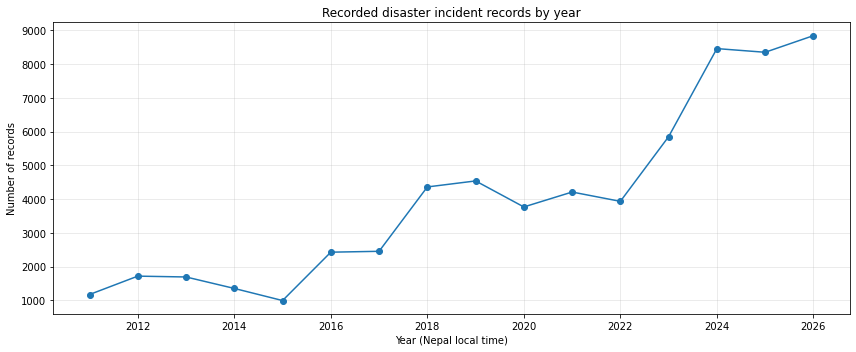

In [6]:
yearly = df.groupby('incident_year').size().rename('incident_count').reset_index()
display(yearly)
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(yearly['incident_year'], yearly['incident_count'], marker='o')
ax.set(title='Recorded disaster incident records by year', xlabel='Year (Nepal local time)', ylabel='Number of records')
ax.grid(alpha=.3)
plt.tight_layout()
plt.show()

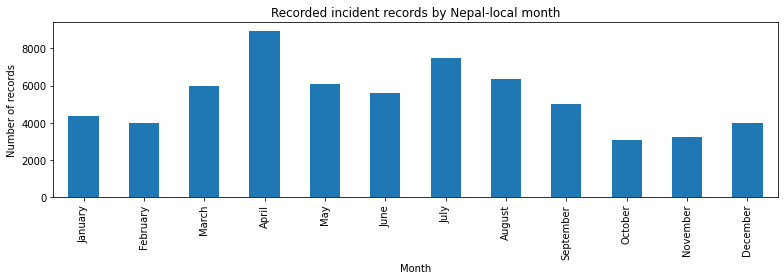

In [7]:
monthly = df.groupby('incident_month').size().reindex(range(1, 13), fill_value=0)
monthly.index = pd.to_datetime(monthly.index, format='%m').month_name()
ax = monthly.plot(kind='bar', figsize=(11, 4), title='Recorded incident records by Nepal-local month')
ax.set_xlabel('Month')
ax.set_ylabel('Number of records')
plt.tight_layout()
plt.show()

**Caution:** counts describe records in this extract, not necessarily the complete true number of disasters. Reporting practices and incomplete calendar years may affect trends. The dataset ends in September 2026, so 2026 is a partial year.

## 3. Hazard IDs and recorded impacts

,hazard_name,incident_count
0,Fire,34718
1,Landslide,6493
2,Thunderbolt,4133
3,Heavy Rainfall,3443
4,Flood,3112
5,Animal Incidents,3018
6,Forest Fire,2510
7,Snake Bite,2377
8,Wind storm,2272
9,Drowning,515


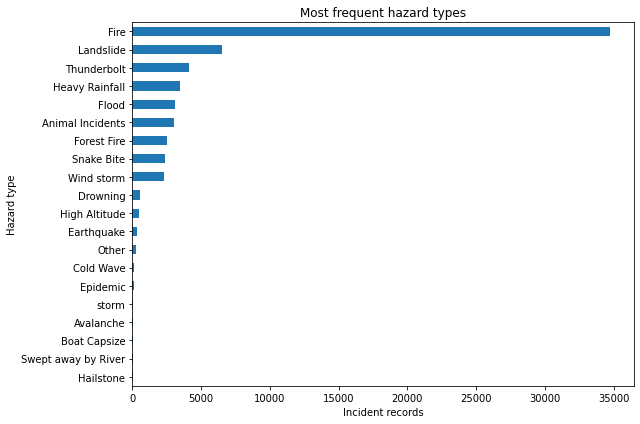

In [8]:
hazard_counts = (
    df["hazard_name"]
    .dropna()
    .value_counts()
    .head(20)
    .rename_axis("hazard_name")
    .reset_index(name="incident_count")
)

display(hazard_counts)

ax = hazard_counts.sort_values("incident_count").plot(
    kind="barh",
    x="hazard_name",
    y="incident_count",
    legend=False,
    figsize=(9, 6),
    title="Most frequent hazard types",
)

ax.set_xlabel("Incident records")
ax.set_ylabel("Hazard type")
plt.tight_layout()
plt.show()

In [9]:
impact_cols = [
    'peopleDeathCount', 'peopleMissingCount', 'peopleInjuredCount', 'peopleAffectedCount',
    'familyAffectedCount', 'familyRelocatedCount', 'familyEvacuatedCount',
    'livestockDestroyedCount', 'infrastructureDestroyedCount', 'estimatedLoss'
]
display(df[impact_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
peopleDeathCount,64131.0,2.678736e-01,1.626084e+01,0.0,0.0,0.0,0.0,3.570000e+03
peopleMissingCount,64131.0,2.365471e-02,8.869791e-01,0.0,0.0,0.0,0.0,1.390000e+02
peopleInjuredCount,64131.0,6.699100e-01,3.711157e+01,0.0,0.0,0.0,0.0,7.950000e+03
peopleAffectedCount,64131.0,0.000000e+00,0.000000e+00,0.0,0.0,0.0,0.0,0.000000e+00
familyAffectedCount,64131.0,4.080351e+00,1.651958e+02,0.0,1.0,1.0,1.0,2.581500e+04
familyRelocatedCount,64131.0,2.494893e-03,5.166131e-01,0.0,0.0,0.0,0.0,1.300000e+02
familyEvacuatedCount,64131.0,0.000000e+00,0.000000e+00,0.0,0.0,0.0,0.0,0.000000e+00
livestockDestroyedCount,64131.0,4.713633e-01,1.069655e+01,0.0,0.0,0.0,0.0,2.000000e+03
infrastructureDestroyedCount,64131.0,1.317798e+01,8.602951e+02,0.0,0.0,0.0,0.0,8.988400e+04
estimatedLoss,31831.0,1.759866e+06,6.323334e+07,0.0,80000.0,204000.0,600000.0,1.005285e+10


In [10]:
impact_by_hazard = df.groupby('hazard')[impact_cols].sum(numeric_only=True).sort_values('peopleDeathCount', ascending=False)
display(impact_by_hazard.head(20))
impact_by_hazard.to_csv(ROOT / 'reports' / 'impact_by_hazard_id.csv')

,peopleDeathCount,peopleMissingCount,peopleInjuredCount,peopleAffectedCount,familyAffectedCount,familyRelocatedCount,familyEvacuatedCount,livestockDestroyedCount,infrastructureDestroyedCount,estimatedLoss
hazard,,,,,,,,,,
8,9131,195,22743,0,68031,1,0,407,799810,2.478590e+09
17,1993,415,1711,0,21489,131,0,7197,6473,2.102543e+09
23,1343,1,4062,0,4741,0,0,5272,175,1.378555e+08
10,1229,0,4613,0,45166,15,0,12158,21815,3.170029e+10
11,1064,636,296,0,75559,11,0,1382,12097,1.782793e+10
7,418,126,19,0,512,0,0,0,1,0.000000e+00
2,359,2,1843,0,4783,0,0,1551,134,9.205260e+07
45,356,50,294,0,5878,0,0,56,43,2.163470e+07
20,346,0,2050,0,2389,0,0,0,0,0.000000e+00


## 4. Economic loss missingness

,records
missing,32300
reported zero,866
reported positive,30965


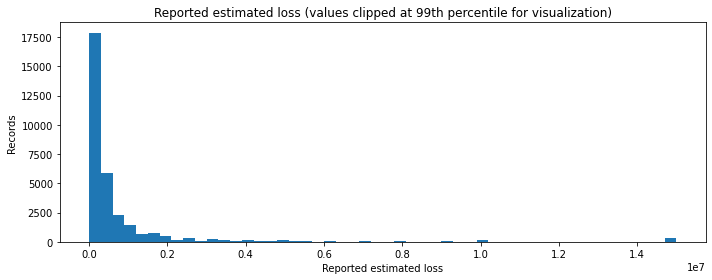

In [11]:
loss_status = pd.Series({
    'missing': df['estimatedLoss'].isna().sum(),
    'reported zero': (df['estimatedLoss'] == 0).sum(),
    'reported positive': (df['estimatedLoss'] > 0).sum(),
}, name='records')
display(loss_status.to_frame())
reported_loss = df.loc[df['estimatedLoss'].notna(), 'estimatedLoss']
if len(reported_loss):
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.hist(reported_loss.clip(upper=reported_loss.quantile(.99)), bins=50)
    ax.set(title='Reported estimated loss (values clipped at 99th percentile for visualization)', xlabel='Reported estimated loss', ylabel='Records')
    plt.tight_layout(); plt.show()

Do not convert missing loss values to zero. Before reporting monetary totals, verify the source's currency and units. `hazard` and `event` are IDs unless an authoritative mapping table is added.

## 5. Coordinate coverage

Rows with parseable coordinates: 64131


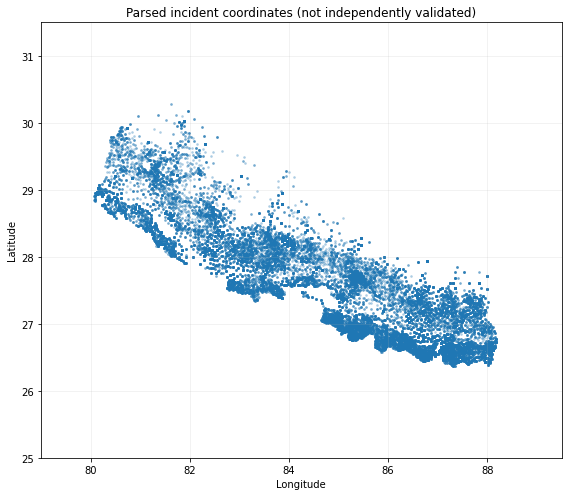

In [12]:
print('Rows with parseable coordinates:', df[['longitude','latitude']].notna().all(axis=1).sum())
geo = df.dropna(subset=['longitude','latitude'])
fig, ax = plt.subplots(figsize=(8, 7))
ax.scatter(geo['longitude'], geo['latitude'], s=3, alpha=.25)
ax.set(xlabel='Longitude', ylabel='Latitude', title='Parsed incident coordinates (not independently validated)')
ax.set_xlim(79, 89.5); ax.set_ylim(25, 31.5); ax.grid(alpha=.2)
plt.tight_layout(); plt.show()

The `point` field is parsed as GeoJSON-like longitude/latitude. The `wards` field contains identifiers, not verified ward names. To identify municipalities or wards robustly, use an authoritative administrative-boundary layer or official lookup dataset and validate the spatial reference system.